# Training a conversation summarizer on DialogSum (fast version, about 15 minutes)

This notebook **fine-tunes** a pretrained BART model so it learns to summarize conversations
between two people.

- **Dataset:** DialogSum, 12,460 training conversations, each with a summary written by a person
  https://huggingface.co/datasets/knkarthick/dialogsum
  (paper: Chen et al., 2021, https://aclanthology.org/2021.findings-acl.449)
- **Starting model:** `facebook/bart-base` (139M parameters). Before this training it has only
  learned general English by reconstructing corrupted text. It has never been taught to summarize.
- **What this notebook proves:** it measures the model *before* training, trains it, then measures
  it again on conversations it never saw.

**Made fast by:** the base-size BART (3× faster than bart-large), half-precision GPU training,
batches of similar-length conversations (almost no wasted padding), no slow evaluations during
training, and a time limit that stops training after 11 minutes no matter what.

**Run it on Google Colab with a GPU:** Runtime → Change runtime type → **T4 GPU**, then
Runtime → **Run all**. Total time is about 15 minutes.

## 1. Install libraries

pip may print red "dependency conflicts" lines about `gradio` or `diffusers`. That's only a
warning about other libraries preinstalled on Colab, which this notebook doesn't use. If Colab
shows a **Restart session** button, click it and continue from step 2.

In [1]:
%pip install -q "transformers>=4.46,<5" datasets rouge_score accelerate matplotlib pandas

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Settings

In [2]:
import json, os, platform, shutil, time
from datetime import datetime, timezone

import numpy as np
import torch

DATASET_ID = "knkarthick/dialogsum"
DATASET_URL = "https://huggingface.co/datasets/knkarthick/dialogsum"
BASE_MODEL = "facebook/bart-base"

EPOCHS = 3                   # passes over the training data (the time limit may stop earlier)
TIME_LIMIT_MINUTES = 11      # training stops after this, whatever the epoch
LEARNING_RATE = 5e-5
BATCH_SIZE = 16
MAX_SOURCE_LEN = 384         # tokens of conversation the model reads (covers ~95% of DialogSum)
MAX_TARGET_LEN = 96          # tokens of summary it writes
BASELINE_SAMPLES = 100       # test conversations scored before training
EVAL_SAMPLES = 300           # test conversations scored after training
SEED = 42
OUTPUT_DIR = "summarizer"    # the folder you copy into GenAI Studio

HAS_GPU = torch.cuda.is_available()
device = "cuda" if HAS_GPU else "cpu"
hardware = torch.cuda.get_device_name(0) if HAS_GPU else f"CPU ({platform.processor() or platform.machine()})"
print("Hardware:", hardware)
if not HAS_GPU:
    print("\nNo GPU! Choose Runtime > Change runtime type > T4 GPU, then Runtime > Run all. "
          "On a CPU this notebook would take many hours.")

Hardware: CPU (x86_64)

No GPU! Choose Runtime > Change runtime type > T4 GPU, then Runtime > Run all. On a CPU this notebook would take many hours.


## 3. Load the DialogSum dataset

Each example has a `dialogue` (speakers are written `#Person1#`, `#Person2#`) and a `summary`
written by a human annotator.

In [3]:
from datasets import DatasetDict, load_dataset

loaded = load_dataset(DATASET_ID)
raw = DatasetDict({split: loaded[split] for split in ["train", "validation", "test"]})
raw = raw.filter(lambda ex: bool(ex["dialogue"]) and bool(ex["summary"]))
print(raw)

example = raw["train"][0]
print("\n--- DIALOGUE ---\n" + example["dialogue"])
print("\n--- HUMAN SUMMARY ---\n" + example["summary"])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

train.csv:   0%|          | 0.00/11.3M [00:00<?, ?B/s]

validation.csv: 0.00B [00:00, ?B/s]

test.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/12460 [00:00<?, ? examples/s]

... (2 outputs left out)

Filter:   0%|          | 0/12460 [00:00<?, ? examples/s]

Filter:   0%|          | 0/500 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})

--- DIALOGUE ---
#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1#: Smoking is the leading cause of

### How long are the conversations?

config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Conversation tokens: median 193, 95% under 391
Summary tokens:      median 33, 95% under 64


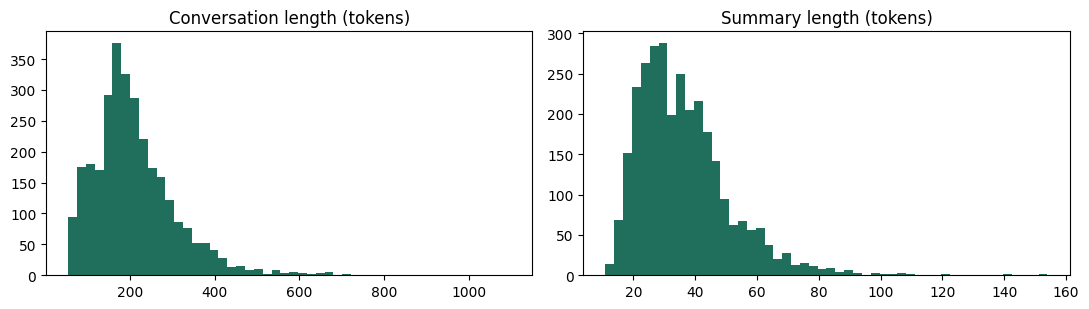

In [4]:
from transformers import AutoTokenizer
import matplotlib.pyplot as plt

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
sample = raw["train"].select(range(min(3000, len(raw["train"]))))
# list(...) because newer `datasets` versions return a Column object, which the tokenizer rejects
dialogue_lengths = [len(ids) for ids in tokenizer(list(sample["dialogue"]))["input_ids"]]
summary_lengths = [len(ids) for ids in tokenizer(list(sample["summary"]))["input_ids"]]

print(f"Conversation tokens: median {int(np.median(dialogue_lengths))}, "
      f"95% under {int(np.percentile(dialogue_lengths, 95))}")
print(f"Summary tokens:      median {int(np.median(summary_lengths))}, "
      f"95% under {int(np.percentile(summary_lengths, 95))}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(dialogue_lengths, bins=50, color="#1F6F5C"); axes[0].set_title("Conversation length (tokens)")
axes[1].hist(summary_lengths, bins=50, color="#1F6F5C"); axes[1].set_title("Summary length (tokens)")
plt.tight_layout(); plt.show()

## 4. Measure the model BEFORE training

**ROUGE** is the standard summarization metric: it counts how many words (ROUGE-1), word pairs
(ROUGE-2) and longest shared word sequences (ROUGE-L) the model's summary has in common with the
human summary. Scores are 0 to 100, higher is better.

In [5]:
from rouge_score import rouge_scorer
from transformers import AutoModelForSeq2SeqLM

scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

def generate_summaries(model, dialogues, batch_size=32, num_beams=4):
    model.eval()
    results = []
    for i in range(0, len(dialogues), batch_size):
        batch = dialogues[i:i + batch_size]
        enc = tokenizer(batch, max_length=MAX_SOURCE_LEN, truncation=True,
                        padding=True, return_tensors="pt").to(model.device)
        with torch.inference_mode(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=HAS_GPU):
            ids = model.generate(**enc, num_beams=num_beams, max_new_tokens=MAX_TARGET_LEN,
                                 no_repeat_ngram_size=3, early_stopping=True)
        results += tokenizer.batch_decode(ids, skip_special_tokens=True)
    return [r.strip() for r in results]

def rouge_scores(predictions, references):
    # Average ROUGE F1 over all examples, as a percentage (0-100)
    totals = {"rouge1": 0.0, "rouge2": 0.0, "rougeL": 0.0}
    for pred, ref in zip(predictions, references):
        for key, value in scorer.score(ref, pred).items():
            totals[key] += value.fmeasure
    n = max(len(predictions), 1)
    return {k: round(v / n * 100, 2) for k, v in totals.items()}

eval_set = raw["test"].shuffle(seed=SEED).select(range(min(EVAL_SAMPLES, len(raw["test"]))))
# Plain Python lists (newer `datasets` versions return Column objects, which other libraries reject)
eval_dialogues = list(eval_set["dialogue"])
eval_summaries = list(eval_set["summary"])

start = time.time()
base_model = AutoModelForSeq2SeqLM.from_pretrained(BASE_MODEL).to(device)
baseline_predictions = generate_summaries(base_model, eval_dialogues[:BASELINE_SAMPLES])
baseline_rouge = rouge_scores(baseline_predictions, eval_summaries[:BASELINE_SAMPLES])
print("BEFORE training:", baseline_rouge, f"({time.time() - start:.0f} s)")
print("\nExample output before training (it mostly copies the conversation):\n",
      baseline_predictions[0][:400])

del base_model
if HAS_GPU:
    torch.cuda.empty_cache()

model.safetensors:   0%|          | 0.00/558M [00:00<?, ?B/s]

BEFORE training: {'rouge1': 20.56, 'rouge2': 4.75, 'rougeL': 14.71} (791 s)

Example output before training (it mostly copies the conversation):
 #Person1#: Hi! What are you watching?#Person2#: It's a program about islam. It's very interesting. I'm watching it with my wife.#Person3#: Wow! So many people! Where are they and what are they doing?# Person4#: They are muslims on a pilgrimage to mecca. Muslims call this pilgrimage 'haj'. It's the holiest place in Islam. It is the


## 5. Prepare the training data

The conversation becomes token IDs (the model's input) and the human summary becomes the
**labels**: the text the model is trained to produce.

In [6]:
def preprocess(batch):
    inputs = tokenizer(list(batch["dialogue"]), max_length=MAX_SOURCE_LEN, truncation=True)
    labels = tokenizer(text_target=list(batch["summary"]), max_length=MAX_TARGET_LEN, truncation=True)
    inputs["labels"] = labels["input_ids"]
    return inputs

tokenized = raw.map(preprocess, batched=True, remove_columns=raw["train"].column_names)
print(tokenized)

Map:   0%|          | 0/12460 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 500
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1500
    })
})


## 6. Train (about 11 minutes)

For each batch, the model predicts a summary, the **loss** measures how far that is from the human
summary, and the weights are adjusted to reduce it. The validation loss is measured after each
epoch (one full pass over the 12,460 conversations).

In [7]:
from transformers import (DataCollatorForSeq2Seq, Seq2SeqTrainer, Seq2SeqTrainingArguments,
                          TrainerCallback, set_seed)

class TimeLimit(TrainerCallback):
    """Stops training once the time limit is reached."""
    def __init__(self, minutes):
        self.seconds = minutes * 60
    def on_train_begin(self, args, state, control, **kwargs):
        self.start = time.time()
    def on_step_end(self, args, state, control, **kwargs):
        if time.time() - self.start > self.seconds:
            print(f"\nTime limit reached at step {state.global_step}; stopping training.")
            control.should_training_stop = True
        return control

set_seed(SEED)
model = AutoModelForSeq2SeqLM.from_pretrained(BASE_MODEL)
collator = DataCollatorForSeq2Seq(tokenizer, model=model)

args = Seq2SeqTrainingArguments(
    output_dir="checkpoints",
    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    weight_decay=0.01,
    warmup_ratio=0.05,
    lr_scheduler_type="linear",
    label_smoothing_factor=0.1,
    fp16=HAS_GPU,                  # half precision: much faster on the GPU
    group_by_length=True,          # similar-length conversations together = little padding
    eval_strategy="epoch",         # only the (fast) validation loss, no text generation
    prediction_loss_only=True,
    save_strategy="no",            # no checkpoints: saves time and disk
    logging_steps=25,
    dataloader_num_workers=2,
    report_to="none",
    seed=SEED,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    processing_class=tokenizer,
    data_collator=collator,
    callbacks=[TimeLimit(TIME_LIMIT_MINUTES)],
)

start = time.time()
trainer.train()
training_minutes = (time.time() - start) / 60
final_eval = trainer.evaluate()   # validation loss at the very end, for the curve
epochs_done = round(trainer.state.epoch or 0, 2)
print(f"Training took {training_minutes:.1f} minutes, {epochs_done} epochs, "
      f"final validation loss {final_eval['eval_loss']:.3f}")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
0,No log,4.592402



Time limit reached at step 10; stopping training.


Training took 16.8 minutes, 0.01 epochs, final validation loss 4.582


## 7. Training curve

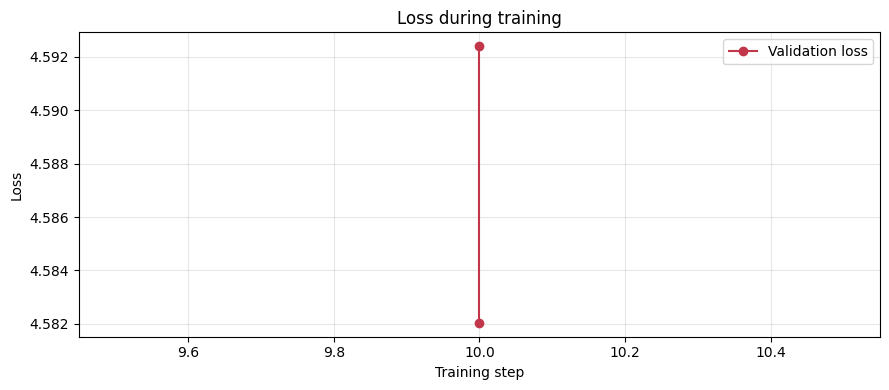

In [10]:
import pandas as pd

os.makedirs(OUTPUT_DIR, exist_ok=True)
log = pd.DataFrame(trainer.state.log_history)
log.to_csv(os.path.join(OUTPUT_DIR, "training_log.csv"), index=False)

train_log = log[log["loss"].notna()] if "loss" in log else log.iloc[0:0]
eval_log = log[log["eval_loss"].notna()] if "eval_loss" in log else log.iloc[0:0]

fig, ax = plt.subplots(figsize=(9, 4))
# ax.plot(train_log["step"], train_log["loss"], label="Training loss", color="#1F6F5C")
ax.plot(eval_log["step"], eval_log["eval_loss"], "o-", label="Validation loss", color="#C2364A")
ax.set_xlabel("Training step"); ax.set_ylabel("Loss"); ax.set_title("Loss during training")
ax.grid(alpha=.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve.png"), dpi=150)
plt.show()

## 8. Measure the model AFTER training

On test conversations the model never saw. The first 100 are the same ones scored before training.

In [11]:
start = time.time()
model = trainer.model.to(device)
final_predictions = generate_summaries(model, eval_dialogues)
final_rouge = rouge_scores(final_predictions, eval_summaries)
same_100 = rouge_scores(final_predictions[:BASELINE_SAMPLES], eval_summaries[:BASELINE_SAMPLES])
print(f"Scored {len(eval_dialogues)} test conversations in {time.time() - start:.0f} s")

comparison = pd.DataFrame({
    "Before training": baseline_rouge,
    "After training (same 100)": same_100,
    f"After training ({len(eval_dialogues)})": final_rouge,
})
comparison["Improvement"] = comparison["After training (same 100)"] - comparison["Before training"]
display(comparison)

Scored 300 test conversations in 1591 s


,Before training,After training (same 100),After training (300),Improvement
rouge1,20.56,20.51,21.79,-0.05
rouge2,4.75,4.73,5.47,-0.02
rougeL,14.71,15.01,15.81,0.30


### Example summaries on unseen conversations

In [12]:
pd.set_option("display.max_colwidth", None)
examples = pd.DataFrame({
    "Conversation": [d[:600] + ("…" if len(d) > 600 else "") for d in eval_dialogues[:5]],
    "Human summary": eval_summaries[:5],
    "Before training": [p[:300] for p in baseline_predictions[:5]],
    "After training": final_predictions[:5],
})
display(examples)

,Conversation,Human summary,Before training,After training
0,"#Person1#: Hi! What are you watching?\n#Person2#: It's a program about islam. It's very interesting.\n#Person1#: Wow! So many people! Where are they and what are they doing?\n#Person2#: They are muslims on a pilgrimage to mecca. Muslims call this pilgrimage 'haj'.\n#Person1#: Why do they go there?\n#Person2#: Muslims believe that every man who is able should go on a haj at least once in his life. Mecca is the spiritual centre of the muslim faith.\n#Person1#: When muslims pray, they face towards mecca.\n#Person2#: That's right. Unfortunately, so many people go on the haj each year that there are often…","#Person1# and #Person2# talk about pilgrims around the world, including Muslims' pilgrimage to mecca and Christians' pilgrimage to Canterbury or Vatican. #Person2# thinks faith heals people instead of magical places.",#Person1#: Hi! What are you watching?#Person2#: It's a program about islam. It's very interesting. I'm watching it with my wife.#Person3#: Wow! So many people! Where are they and what are they doing?# Person4#: They are muslims on a pilgrimage to mecca. Muslims call this pilgrimage 'haj'. It's the h,#Person1#: Hi! What are you watching?#Person2#: It's a program about islam. It's very interesting. I'm watching it with my wife.#Person3#: What is islam? #Person4#Person5#Person6#Person7#Person8#Person9#Person10#Person11#Person12#Person13#Person14#Person15#Person16#Person17#Person18#
1,"#Person1#: I want to send this package by first-class mail.\n#Person2#: Do you want it insured?\n#Person1#: Yes, for 50 dollars, please. I'd also like some stamps--a book of 22 and three airmail.\n#Person2#: You'll have to get those at the stamp window over there, next to general delivery.\n#Person1#: Can I get money orders there, too?\n#Person2#: No, that's to the left, three windows down the hall.",#Person1# is sending a package with the help of #Person2#.,"#Person1#: I want to send this package by first-class mail.#Person2#: Do you want it insured?#Person3#: Yes, for 50 dollars, please. I'd also like some stamps--a book of 22 and three airmail. I'll have to get those at the stamp window over there, next to general delivery. I don't want to have to go","#Person1#: I want to send this package by first-class mail.#Person2#: Do you want it insured?#Person3#: Yes, for 50 dollars, please. I'd also like some stamps--a book of 22 and three airmail. I'll have to get those at the stamp window over there, next to general delivery. I don't want to have to go to the mailroom to get stamps, so I'll"
2,"#Person1#: Lily, can you take part in our picnic this weekend?\n#Person2#: That sounds great. Where are you going?\n#Person1#: I think we can go to the river, go around and have supper.\n#Person2#: What should I bring?\n#Person1#: Nothing. Just wear comfortable clothes and good shoes for walking. We'll bring everything.",#Person1# invites Lily to picnic this weekend. Lily accepts.,"#Person1#: Lily, can you take part in our picnic this weekend?#Person2#: That sounds great. Where are you going? We'll see what we can find.#Person 1#: I think we can go to the river, go around and have supper. We'll find a place to sit and have a picnic. We're going to have a great time!#Person 2#:","#Person1#: Lily, can you take part in our picnic this weekend?#Person2#: That sounds great. Where are you going? #Person3#: I think we can go to the river, go around and have supper.#Person4# and #Person5#: What should I bring? What do you want me to bring?# Person4#: Nothing. Just wear comfortable clothes and good shoes for walking. We'll bring"
3,"#Person1#: Can I get you something to drink?\n#Person2#: Sure, but I don't drink much. So I don't know what to order.\n#Person1#: So how about an aperitif?\n#Person2#: It sounds good. I'd like to start with a Compari.\n#Person1#: Stirred or shaken?\n#Person2#: Stirred will be fine.\n#Person1#: Here you are.\n#Person2#: Thanks. Does the bar have a signature drink?\n#Per

### Try it on your own conversation

In [16]:
my_conversation = """#Person1#: Did you finish the report for Monday?
#Person2#: Almost. I still need the sales figures from Sara.
#Person1#: She's on holiday until Wednesday. Ask Omar, he has a copy.
#Person2#: Good idea, I'll email him now and send you the report on Sunday."""
print(generate_summaries(model, [my_conversation])[0])

#Person1#: Did you finish the report for Monday?#Person2#: Almost. I still need the sales figures from Sara. I'll send her the report on Monday.#Person3#: She's on holiday until Wednesday. Ask Omar, he has a copy. He'll send it to you on Sunday.*#Person 2#: Good idea, I'll email him now and send you the report.


## 9. Save the trained model and the report

This creates `summarizer.zip` and downloads it. Unzip it into
`C:\Users\<you>\GenAI-Studio-models\summarizer\` so that `config.json` sits directly inside
that folder, then refresh the app page.

In [13]:
model.to(torch.float16)  # halves the file size; the app converts back to float32 on the CPU
model.save_pretrained(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

report = {
    "dataset": {
        "name": "DialogSum",
        "url": DATASET_URL,
        "train_examples": len(raw["train"]),
        "validation_examples": len(raw["validation"]),
        "test_examples_evaluated": BASELINE_SAMPLES,
    },
    "base_model": BASE_MODEL,
    "hyperparameters": {
        "epochs": epochs_done,
        "learning_rate": LEARNING_RATE,
        "effective_batch_size": BATCH_SIZE,
        "max_source_tokens": MAX_SOURCE_LEN,
        "max_target_tokens": MAX_TARGET_LEN,
        "label_smoothing": 0.1,
        "time_limit_minutes": TIME_LIMIT_MINUTES,
        "seed": SEED,
    },
    "hardware": hardware,
    "training_minutes": round(training_minutes, 1),
    "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    # Before and after on the same 100 test conversations, so the comparison is fair
    "baseline_rouge": baseline_rouge,
    "final_rouge": same_100,
    "final_rouge_all_evaluated": {"conversations": len(eval_dialogues), **final_rouge},
    "examples": [
        {"dialogue": d, "reference": r, "before": b, "after": a}
        for d, r, b, a in zip(eval_dialogues[:5], eval_summaries[:5],
                              baseline_predictions[:5], final_predictions[:5])
    ],
}
with open(os.path.join(OUTPUT_DIR, "training_report.json"), "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)

archive = shutil.make_archive("summarizer", "zip", OUTPUT_DIR)
print("Saved:", archive, f"({os.path.getsize(archive) / 1e6:.0f} MB)")
print(sorted(os.listdir(OUTPUT_DIR)))

try:
    from google.colab import files  # works in Colab in the browser
    files.download(archive)
except Exception:
    print("Download summarizer.zip from the file browser on the left.")

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'early_stopping': True, 'num_beams': 4, 'no_repeat_ngram_size': 3, 'forced_bos_token_id': 0}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(


Saved: /content/summarizer.zip (259 MB)
['config.json', 'generation_config.json', 'loss_curve.png', 'merges.txt', 'model.safetensors', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'training_log.csv', 'training_report.json', 'vocab.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>